<a href="https://colab.research.google.com/github/MaryamAmjad2/Predicting-Wind-Speed-with-LSTM/blob/main/Predicting_Wind_Speed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Step 1: Clean Data


In [27]:
# 1. Load the CSV file
df = pd.read_csv('pakistan_weather_data-Sep2024-Oct2025.csv')

# 2. Drop completely empty columns (visibility)
df = df.drop(columns=['visibility'], errors='ignore')

# 3. Select continuous features for weather & wind-field forecasting
feature_cols = ['tavg', 'tmin', 'tmax', 'prcp', 'wspd', 'humidity', 'pressure', 'dew_point', 'cloud_cover']

# 4. Clean missing/null values if any exist in features
df[feature_cols] = df.groupby('city')[feature_cols].ffill().bfill()

# 5. Normalize features across the dataset
scaler = StandardScaler()
scaled_df = df.copy()
scaled_df[feature_cols] = scaler.fit_transform(df[feature_cols])

print("Cleaned & Normalized Shape:", scaled_df.shape)
print("Features Ready:", feature_cols)

Cleaned & Normalized Shape: (2466, 26)
Features Ready: ['tavg', 'tmin', 'tmax', 'prcp', 'wspd', 'humidity', 'pressure', 'dew_point', 'cloud_cover']


# Step 2: PyTorch Sliding-Window Generator

In [17]:
import torch
from torch.utils.data import Dataset, DataLoader

class MeteorologicalDataset(Dataset):
    def __init__(self, data_df, feature_cols, target_col='wspd', seq_len=14):
        self.sequences = []
        self.targets = []
        target_idx = feature_cols.index(target_col)

        # Group by city and use implicit sequential row order
        for city, group in data_df.groupby('city'):
            vals = group[feature_cols].values

            # Slide window across the 411 records of each city
            for i in range(len(vals) - seq_len):
                x_seq = vals[i : i + seq_len]             # Historical window (14 timesteps)
                y_val = vals[i + seq_len, target_idx]     # Target prediction (next step)

                self.sequences.append(x_seq)
                self.targets.append(y_val)

        self.sequences = torch.tensor(np.array(self.sequences), dtype=torch.float32)
        self.targets = torch.tensor(np.array(self.targets), dtype=torch.float32).unsqueeze(-1)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.targets[idx]

# Instantiate dataset with a 14-step lookback window
SEQ_LEN = 14
TARGET_COL = 'wspd'
BATCH_SIZE = 32

dataset = MeteorologicalDataset(scaled_df, feature_cols, target_col=TARGET_COL, seq_len=SEQ_LEN)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

# Verify tensor batch shapes
sample_x, sample_y = next(iter(dataloader))
print(f"Total training sliding windows created: {len(dataset):,}")
print(f"X Tensor Batch Shape [Batch, Seq_Len, Features]: {sample_x.shape}")
print(f"Y Tensor Batch Shape [Batch, Target_Dim]: {sample_y.shape}")

Total training sliding windows created: 2,382
X Tensor Batch Shape [Batch, Seq_Len, Features]: torch.Size([32, 14, 9])
Y Tensor Batch Shape [Batch, Target_Dim]: torch.Size([32, 1])


# Step 3: Building Spatial-Temporal Neural Network

In [20]:


class WeatherLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, output_dim=1, dropout=0.2):
        super(WeatherLSTM, self).__init__()

        # LSTM layer to process temporal weather sequences
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        # Fully connected layers to map hidden states to our target prediction
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, output_dim)
        )

    def forward(self, x):
        # x shape: [Batch, Seq_Len, Features]
        out, (hn, cn) = self.lstm(x)

        # Take the output from the last time step in the sequence
        last_step_out = out[:, -1, :]

        # Pass through fully connected layers
        predictions = self.fc(last_step_out)
        return predictions

# Model Hyperparameters
INPUT_DIM = len(feature_cols) # 9 features
model = WeatherLSTM(input_dim=INPUT_DIM, hidden_dim=64, num_layers=2, output_dim=1)

# Loss function (Mean Squared Error for regression) and Optimizer (AdamW)
criterion = nn.MSELoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

print(model)
print(f"\nTotal trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

WeatherLSTM(
  (lstm): LSTM(9, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)

Total trainable parameters: 54,593


# Step 4: Training Loop

In [21]:
# Training Loop
EPOCHS = 15
model.train()

for epoch in range(EPOCHS):
    epoch_loss = 0.0

    for batch_x, batch_y in dataloader:
        # 1. Zero gradients
        optimizer.zero_grad()

        # 2. Forward pass
        predictions = model(batch_x)

        # 3. Calculate loss
        loss = criterion(predictions, batch_y)

        # 4. Backward pass & optimize
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * batch_x.size(0)

    avg_epoch_loss = epoch_loss / len(dataset)
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Loss (MSE): {avg_epoch_loss:.4f}")

print("\nModel training complete!")

Epoch [1/15] | Loss (MSE): 0.5638
Epoch [2/15] | Loss (MSE): 0.3372
Epoch [3/15] | Loss (MSE): 0.3214
Epoch [4/15] | Loss (MSE): 0.3117
Epoch [5/15] | Loss (MSE): 0.3009
Epoch [6/15] | Loss (MSE): 0.2805
Epoch [7/15] | Loss (MSE): 0.2692
Epoch [8/15] | Loss (MSE): 0.2569
Epoch [9/15] | Loss (MSE): 0.2546
Epoch [10/15] | Loss (MSE): 0.2560
Epoch [11/15] | Loss (MSE): 0.2561
Epoch [12/15] | Loss (MSE): 0.2509
Epoch [13/15] | Loss (MSE): 0.2484
Epoch [14/15] | Loss (MSE): 0.2466
Epoch [15/15] | Loss (MSE): 0.2369

Model training complete!


# Step 5: Visualize

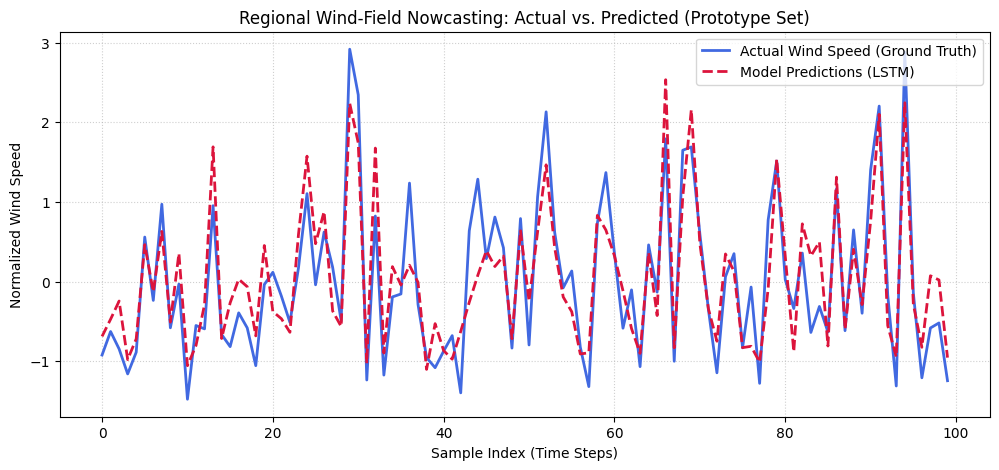

In [25]:
model.eval()
actuals = []
predictions = []

with torch.no_grad():
    for batch_x, batch_y in dataloader:
        preds = model(batch_x)
        actuals.extend(batch_y.numpy().flatten())
        predictions.extend(preds.numpy().flatten())

# Plot the first 100 samples of Predicted vs Actual Wind Speed
plt.figure(figsize=(12, 5))
plt.plot(actuals[:100], label='Actual Wind Speed (Ground Truth)', color='royalblue', linewidth=2)
plt.plot(predictions[:100], label='Model Predictions (LSTM)', color='crimson', linestyle='--', linewidth=2)
plt.title('Regional Wind-Field Nowcasting: Actual vs. Predicted (Prototype Set)')
plt.xlabel('Sample Index (Time Steps)')
plt.ylabel('Normalized Wind Speed')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()